# Лабораторная работа 1: повышение разрешения изображения (SRGAN, ×4)

**Задача.** На вход подаётся изображение низкого разрешения (.png / .bmp / .jpg), на выходе получается это же изображение в 4 раза больше по каждой стороне с восстановленными деталями.

**Подход.** Нейросеть SRGAN ([Ledig et al., 2016](https://arxiv.org/abs/1609.04802)), написанная на PyTorch и обученная в два этапа:
1. **SRResNet**: обучается только генератор, ошибка считается попиксельно (MSE).
2. **SRGAN**: генератор дообучается вместе с дискриминатором. Ошибка складывается из попиксельного сравнения, сравнения признаков VGG19 и ошибки «обмана» дискриминатора.

**Данные.** DIV2K: 700 фото для обучения, 100 для проверки. Уменьшенные копии создаются через `cv2.resize`.

**Оценка.** PSNR, SSIM и LPIPS, сравнение с обычным увеличением (bicubic).

## 1. Подготовка

In [1]:
import os
import random
import time
import warnings
import zipfile
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# Скрытие служебных предупреждений библиотек
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Вычисления на видеокарте
DEVICE = torch.device("cuda")

# Одинаковые случайные числа при каждом запуске
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Папка для распакованного датасета
DATA_DIR = Path("data")
# Папка для сохранений обучения
CKPT_DIR = Path("checkpoints")
# Папка для увеличенных своих фото
RESULTS_DIR = Path("results")
for folder in (DATA_DIR, CKPT_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Во сколько раз увеличивается каждая сторона изображения
SCALE = 4
# Размер куска большого изображения для обучения
HR_PATCH = 96

## 2. Данные

In [2]:
# Распаковка DIV2K из архива
TRAIN_DIR = DATA_DIR / "DIV2K_train_HR"
if not TRAIN_DIR.exists():
    with zipfile.ZipFile(Path("..", "..", "DIV2K_train_HR.zip")) as archive:
        archive.extractall(DATA_DIR)

# Первые 700 фото для обучения, последние 100 для проверки качества
all_files = sorted(TRAIN_DIR.glob("*.png"))
train_files = all_files[:700]
valid_files = all_files[700:]

print("Обучающих фото:", len(train_files))
print("Проверочных фото:", len(valid_files))

Обучающих фото: 700
Проверочных фото: 100


In [3]:
def load_image(path):
    # Читает фото с диска в цветовом порядке RGB
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Не удалось прочитать {path}: нужен файл .png, .bmp или .jpg")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def downscale(img):
    # Уменьшает фото в SCALE раз; INTER_AREA усредняет соседние пиксели и не даёт ряби
    h, w = img.shape[:2]
    return cv2.resize(img, (w // SCALE, h // SCALE), interpolation=cv2.INTER_AREA)


def to_tensor(img):
    # Переводит фото из массива со значениями 0..255 в тензор 0..1 формы (каналы, высота, ширина)
    return torch.from_numpy(img.transpose(2, 0, 1).copy()).float() / 255.0


class SRDataset(Dataset):
    # Набор пар «маленький кусок → большой кусок» из случайных мест обучающих фото

    def __init__(self, images, repeats):
        # images — фото в памяти, repeats — сколько кусков берётся из каждого фото за эпоху
        self.images = images
        self.repeats = repeats

    def __len__(self):
        # Количество пар за одну эпоху
        return len(self.images) * self.repeats

    def __getitem__(self, idx):
        # Вырезает случайный кусок фото, случайно отражает и поворачивает его, создаёт уменьшенную копию
        img = self.images[idx % len(self.images)]
        h, w = img.shape[:2]
        y = random.randint(0, h - HR_PATCH)
        x = random.randint(0, w - HR_PATCH)
        hr = img[y:y + HR_PATCH, x:x + HR_PATCH]

        # Отражения и повороты делают данные разнообразнее
        if random.random() < 0.5:
            hr = hr[:, ::-1]
        hr = np.ascontiguousarray(np.rot90(hr, random.randint(0, 3)))

        lr = downscale(hr)
        return to_tensor(lr), to_tensor(hr)


# Загрузка обучающих фото в оперативную память
train_images = [load_image(p) for p in tqdm(train_files, desc="Загрузка фото")]

# Количество пар в одной порции обучения
BATCH_SIZE = 16

# Порции готовятся в основном процессе (num_workers=0)
train_loader = DataLoader(
    SRDataset(train_images, repeats=16),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True,
)

Загрузка фото:   0%|          | 0/700 [00:00<?, ?it/s]

## 3. Модели

In [4]:
from torchvision.models import vgg19, VGG19_Weights


class ResidualBlock(nn.Module):
    # Блок генератора: две свёртки, результат прибавляется ко входу, чтобы не терять исходную информацию

    def __init__(self, channels):
        # channels — количество каналов на входе и выходе блока
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
            nn.PReLU(),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
        )

    def forward(self, x):
        # Вход плюс поправка, найденная свёртками
        return x + self.body(x)


class UpsampleBlock(nn.Module):
    # Блок увеличения картинки в 2 раза: свёртка готовит в 4 раза больше каналов, PixelShuffle раскладывает их в пиксели

    def __init__(self, channels):
        # channels — количество каналов на входе и выходе блока
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(channels, channels * 4, 3, padding=1),
            nn.PixelShuffle(2),
            nn.PReLU(),
        )

    def forward(self, x):
        # Увеличенная в 2 раза по каждой стороне карта признаков
        return self.body(x)


class Generator(nn.Module):
    # Генератор SRGAN: превращает маленькую картинку в картинку в 4 раза больше

    def __init__(self, channels=64, num_blocks=16):
        # channels — ширина сети, num_blocks — количество блоков ResidualBlock
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, channels, 9, padding=4), nn.PReLU())
        self.blocks = nn.Sequential(*[ResidualBlock(channels) for _ in range(num_blocks)])
        self.after_blocks = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
        )
        # Два увеличения по 2 раза дают итоговое увеличение в 4 раза
        self.upsample = nn.Sequential(UpsampleBlock(channels), UpsampleBlock(channels))
        self.tail = nn.Conv2d(channels, 3, 9, padding=4)

    def forward(self, x):
        # Признаки картинки -> уточнение блоками -> увеличение -> сборка цветной картинки
        head = self.head(x)
        x = head + self.after_blocks(self.blocks(head))
        return self.tail(self.upsample(x))


def disc_block(in_ch, out_ch, stride):
    # Блок дискриминатора: свёртка, нормализация, активация; stride=2 уменьшает картинку вдвое
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.LeakyReLU(0.2),
    )


class Discriminator(nn.Module):
    # Дискриминатор SRGAN: оценивает, настоящее фото на входе или созданное генератором

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.LeakyReLU(0.2),
            disc_block(64, 64, 2),
            disc_block(64, 128, 1),
            disc_block(128, 128, 2),
            disc_block(128, 256, 1),
            disc_block(256, 256, 2),
            disc_block(256, 512, 1),
            disc_block(512, 512, 2),
        )
        # Приведение к размеру 6x6, чтобы дискриминатор работал с кусками любого размера
        self.pool = nn.AdaptiveAvgPool2d(6)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 6 * 6, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 1),
        )

    def forward(self, x):
        # Одно число на картинку: чем больше, тем «настоящее» картинка по мнению дискриминатора
        return self.classifier(self.pool(self.features(x)))


class VGGFeatures(nn.Module):
    # Готовая сеть VGG19 без обучения: выдаёт признаки картинки для сравнения «по смыслу»

    def __init__(self):
        super().__init__()
        # Слои VGG19 до последней активации перед пятым уменьшением (VGG5,4 из статьи)
        self.layers = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).features[:36].eval()
        for p in self.layers.parameters():
            p.requires_grad = False
        # Средние значения и разброс цветов, на которых обучалась VGG19
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # Признаки картинки со значениями 0..1
        return self.layers((x - self.mean) / self.std)


generator = Generator().to(DEVICE)
vgg = VGGFeatures().to(DEVICE)

## 4. Инструменты оценки качества

In [5]:
# Сторона куска маленького фото, который генератор увеличивает за один раз
TILE = 128
# Запас вокруг куска в пикселях маленького фото: не меньше расстояния, на которое смотрит генератор
TILE_PAD = 40


def crop_to_scale(img):
    # Обрезает края фото так, чтобы стороны делились на SCALE без остатка
    h, w = img.shape[:2]
    return img[:h - h % SCALE, :w - w % SCALE]


def to_image(tensor):
    # Переводит тензор 0..1 формы (1, каналы, высота, ширина) обратно в фото со значениями 0..255
    img = tensor.squeeze(0).clamp(0, 1).permute(1, 2, 0).cpu().numpy()
    return (img * 255.0).round().astype(np.uint8)


@torch.no_grad()
def super_resolve(model, lr_img):
    # Увеличивает фото в SCALE раз генератором по кускам TILE×TILE с запасом TILE_PAD;
    # результат совпадает с увеличением фото целиком. Режим модели после вызова остаётся прежним
    was_training = model.training
    model.eval()
    h, w = lr_img.shape[:2]
    result = np.zeros((h * SCALE, w * SCALE, 3), dtype=np.uint8)
    for y in range(0, h, TILE):
        for x in range(0, w, TILE):
            # Кусок с запасом, обрезанный по краям фото
            y0, x0 = max(y - TILE_PAD, 0), max(x - TILE_PAD, 0)
            y1, x1 = min(y + TILE + TILE_PAD, h), min(x + TILE + TILE_PAD, w)
            part = to_image(model(to_tensor(lr_img[y0:y1, x0:x1]).unsqueeze(0).to(DEVICE)))
            # В результат попадает только сам кусок, без запаса
            th, tw = (min(y + TILE, h) - y) * SCALE, (min(x + TILE, w) - x) * SCALE
            ty, tx = (y - y0) * SCALE, (x - x0) * SCALE
            result[y * SCALE:y * SCALE + th, x * SCALE:x * SCALE + tw] = part[ty:ty + th, tx:tx + tw]
    model.train(was_training)
    return result


def bicubic_upscale(lr_img):
    # Обычное увеличение в SCALE раз без нейросети, для сравнения
    h, w = lr_img.shape[:2]
    return cv2.resize(lr_img, (w * SCALE, h * SCALE), interpolation=cv2.INTER_CUBIC)


def to_y(img):
    # Яркость фото (канал Y): метрики качества в задачах увеличения принято считать по ней
    img = img.astype(np.float64)
    return 16.0 + (65.481 * img[..., 0] + 128.553 * img[..., 1] + 24.966 * img[..., 2]) / 255.0


def psnr(sr, hr):
    # PSNR в децибелах: чем больше, тем ближе результат к оригиналу; полоса шириной SCALE по краям не учитывается
    sr_y = to_y(sr)[SCALE:-SCALE, SCALE:-SCALE]
    hr_y = to_y(hr)[SCALE:-SCALE, SCALE:-SCALE]
    mse = np.mean((sr_y - hr_y) ** 2)
    return 10 * np.log10(255.0 ** 2 / mse)


# Проверочные пары: оригинал и его уменьшенная копия
valid_hr = [crop_to_scale(load_image(p)) for p in tqdm(valid_files, desc="Загрузка проверочных фото")]
valid_lr = [downscale(img) for img in valid_hr]

# Количество проверочных фото для быстрой оценки во время обучения
QUICK_VALID = 10


def quick_psnr(upscale):
    # Средний PSNR на первых QUICK_VALID проверочных фото; upscale — функция увеличения фото
    pairs = zip(valid_lr[:QUICK_VALID], valid_hr[:QUICK_VALID])
    return float(np.mean([psnr(upscale(lr), hr) for lr, hr in pairs]))


print(f"PSNR bicubic: {quick_psnr(bicubic_upscale):.2f} дБ")

Загрузка проверочных фото:   0%|          | 0/100 [00:00<?, ?it/s]

PSNR bicubic: 28.77 дБ


## 5. Этап 1: обучение SRResNet

In [6]:
# Подбор самых быстрых способов вычисления свёрток под размер кусков
torch.backends.cudnn.benchmark = True

# Количество эпох первого этапа
EPOCHS_PRE = 40

mse_loss = nn.MSELoss()


def save_state(path, state):
    # Сохраняет состояние обучения через временный файл, прерванная запись не портит прошлое сохранение
    tmp_path = path.with_name(path.name + ".tmp")
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)


optimizer_g = torch.optim.Adam(generator.parameters(), lr=2e-4)
# Плавное снижение скорости обучения к концу этапа
scheduler_g = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_g, T_max=EPOCHS_PRE)

# История обучения: средняя ошибка и PSNR после каждой эпохи
history_pre = []
pre_state_path = CKPT_DIR / "srresnet_state.pth"
start_epoch = 1

# Продолжение с места остановки, если есть сохранение
if pre_state_path.exists():
    state = torch.load(pre_state_path, map_location="cpu")
    generator.load_state_dict(state["generator"])
    optimizer_g.load_state_dict(state["optimizer"])
    scheduler_g.load_state_dict(state["scheduler"])
    history_pre = state["history"]
    start_epoch = state["epoch"] + 1
    print(f"Найдено сохранение {pre_state_path.name}: пройдено эпох {state['epoch']} из {EPOCHS_PRE}")
    del state

generator.train()
for epoch in range(start_epoch, EPOCHS_PRE + 1):
    start = time.time()
    total_loss = 0.0

    for lr_imgs, hr_imgs in tqdm(train_loader, desc=f"Эпоха {epoch}/{EPOCHS_PRE}", leave=False):
        lr_imgs = lr_imgs.to(DEVICE, non_blocking=True)
        hr_imgs = hr_imgs.to(DEVICE, non_blocking=True)

        sr_imgs = generator(lr_imgs)
        loss = mse_loss(sr_imgs, hr_imgs)

        optimizer_g.zero_grad()
        loss.backward()
        optimizer_g.step()
        total_loss += loss.item()

    scheduler_g.step()

    mean_loss = total_loss / len(train_loader)
    val_psnr = quick_psnr(lambda lr: super_resolve(generator, lr))
    history_pre.append((mean_loss, val_psnr))

    # Сохранение всего состояния обучения после каждой эпохи
    save_state(pre_state_path, {
        "epoch": epoch,
        "history": history_pre,
        "generator": generator.state_dict(),
        "optimizer": optimizer_g.state_dict(),
        "scheduler": scheduler_g.state_dict(),
    })
    print(f"Эпоха {epoch:2d}: ошибка {mean_loss:.5f}, PSNR {val_psnr:.2f} дБ, {time.time() - start:.0f} с")

Эпоха 1/40:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха  1: ошибка 0.01031, PSNR 28.19 дБ, 321 с


Эпоха 2/40:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха  2: ошибка 0.00449, PSNR 27.40 дБ, 109 с


Эпоха 3/40:   0%|          | 0/700 [00:00<?, ?it/s]

...

Эпоха 38: ошибка 0.00284, PSNR 29.74 дБ, 108 с


Эпоха 39/40:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха 39: ошибка 0.00278, PSNR 29.74 дБ, 112 с


Эпоха 40/40:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха 40: ошибка 0.00279, PSNR 29.74 дБ, 110 с


## 6. Этап 2: обучение SRGAN

In [7]:
# Генератор начинает второй этап с весов SRResNet, дискриминатор создаётся заново
generator.load_state_dict(torch.load(pre_state_path, map_location="cpu")["generator"])
discriminator = Discriminator().to(DEVICE)

# Количество эпох второго этапа
EPOCHS_GAN = 10

# Вес попиксельного сравнения с оригиналом: удерживает цвета и форму
PIXEL_WEIGHT = 1.0
# Вес сравнения признаков VGG: добавляет правдоподобные детали (из статьи: 1 / 12.75²)
VGG_WEIGHT = 0.006
# Вес ошибки «обмана» дискриминатора: добавляет резкость (из статьи)
ADV_WEIGHT = 1e-3

bce_loss = nn.BCEWithLogitsLoss()
optimizer_g = torch.optim.Adam(generator.parameters(), lr=1e-4)
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=1e-4)
# Снижение скорости обучения в 10 раз на середине этапа, как в статье
scheduler_g = torch.optim.lr_scheduler.MultiStepLR(optimizer_g, milestones=[EPOCHS_GAN // 2], gamma=0.1)
scheduler_d = torch.optim.lr_scheduler.MultiStepLR(optimizer_d, milestones=[EPOCHS_GAN // 2], gamma=0.1)

# История обучения: ошибки по пикселям, VGG, «обмана», дискриминатора и PSNR после каждой эпохи
history_gan = []
gan_state_path = CKPT_DIR / "srgan_state.pth"
start_epoch = 1

# Продолжение с места остановки, если есть сохранение
if gan_state_path.exists():
    state = torch.load(gan_state_path, map_location="cpu")
    generator.load_state_dict(state["generator"])
    discriminator.load_state_dict(state["discriminator"])
    optimizer_g.load_state_dict(state["optimizer_g"])
    optimizer_d.load_state_dict(state["optimizer_d"])
    scheduler_g.load_state_dict(state["scheduler_g"])
    scheduler_d.load_state_dict(state["scheduler_d"])
    history_gan = state["history"]
    start_epoch = state["epoch"] + 1
    print(f"Найдено сохранение {gan_state_path.name}: пройдено эпох {state['epoch']} из {EPOCHS_GAN}")
    del state

generator.train()
discriminator.train()
for epoch in range(start_epoch, EPOCHS_GAN + 1):
    start = time.time()
    sum_pix, sum_vgg, sum_adv, sum_d = 0.0, 0.0, 0.0, 0.0

    for lr_imgs, hr_imgs in tqdm(train_loader, desc=f"Эпоха {epoch}/{EPOCHS_GAN}", leave=False):
        lr_imgs = lr_imgs.to(DEVICE, non_blocking=True)
        hr_imgs = hr_imgs.to(DEVICE, non_blocking=True)
        sr_imgs = generator(lr_imgs)

        # Обучение дискриминатора: настоящие фото -> 1, созданные генератором -> 0
        real_out = discriminator(hr_imgs)
        fake_out = discriminator(sr_imgs.detach())
        d_loss = (bce_loss(real_out, torch.ones_like(real_out))
                  + bce_loss(fake_out, torch.zeros_like(fake_out)))
        optimizer_d.zero_grad()
        d_loss.backward()
        optimizer_d.step()

        # Обучение генератора: близость к оригиналу по пикселям и признакам VGG плюс «обман» дискриминатора
        pix_loss = mse_loss(sr_imgs, hr_imgs)
        with torch.no_grad():
            hr_features = vgg(hr_imgs)
        vgg_loss = mse_loss(vgg(sr_imgs), hr_features)
        fake_out = discriminator(sr_imgs)
        adv_loss = bce_loss(fake_out, torch.ones_like(fake_out))
        g_loss = PIXEL_WEIGHT * pix_loss + VGG_WEIGHT * vgg_loss + ADV_WEIGHT * adv_loss
        optimizer_g.zero_grad()
        g_loss.backward()
        optimizer_g.step()

        sum_pix += pix_loss.item()
        sum_vgg += vgg_loss.item()
        sum_adv += adv_loss.item()
        sum_d += d_loss.item()

    scheduler_g.step()
    scheduler_d.step()

    n = len(train_loader)
    val_psnr = quick_psnr(lambda lr: super_resolve(generator, lr))
    history_gan.append((sum_pix / n, sum_vgg / n, sum_adv / n, sum_d / n, val_psnr))

    # Сохранение всего состояния обучения после каждой эпохи
    save_state(gan_state_path, {
        "epoch": epoch,
        "history": history_gan,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_g": optimizer_g.state_dict(),
        "optimizer_d": optimizer_d.state_dict(),
        "scheduler_g": scheduler_g.state_dict(),
        "scheduler_d": scheduler_d.state_dict(),
    })
    print(f"Эпоха {epoch:2d}: пиксели {sum_pix / n:.5f}, VGG {sum_vgg / n:.3f}, обман {sum_adv / n:.3f}, "
          f"дискриминатор {sum_d / n:.3f}, PSNR {val_psnr:.2f} дБ, {time.time() - start:.0f} с")

Эпоха 1/10:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха  1: пиксели 0.00381, VGG 0.328, обман 1.222, дискриминатор 1.313, PSNR 29.14 дБ, 467 с


Эпоха 2/10:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха  2: пиксели 0.00395, VGG 0.322, обман 1.150, дискриминатор 1.207, PSNR 28.53 дБ, 459 с


Эпоха 3/10:   0%|          | 0/700 [00:00<?, ?it/s]

...

Эпоха  8: пиксели 0.00412, VGG 0.291, обман 1.176, дискриминатор 1.008, PSNR 28.44 дБ, 448 с


Эпоха 9/10:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха  9: пиксели 0.00412, VGG 0.286, обман 1.174, дискриминатор 0.983, PSNR 28.58 дБ, 443 с


Эпоха 10/10:   0%|          | 0/700 [00:00<?, ?it/s]

Эпоха 10: пиксели 0.00402, VGG 0.285, обман 1.214, дискриминатор 0.985, PSNR 28.15 дБ, 445 с


## 7. Оценка на проверочных фото

In [8]:
import lpips
from skimage.metrics import structural_similarity


def ssim(sr, hr):
    # SSIM от 0 до 1: насколько совпадают структура и контраст результата и оригинала; полоса шириной SCALE по краям не учитывается
    sr_y = to_y(sr)[SCALE:-SCALE, SCALE:-SCALE]
    hr_y = to_y(hr)[SCALE:-SCALE, SCALE:-SCALE]
    return structural_similarity(sr_y, hr_y, data_range=255)


# Сеть для метрики LPIPS
lpips_model = lpips.LPIPS(net="alex", verbose=False).to(DEVICE)


@torch.no_grad()
def lpips_score(sr, hr):
    # LPIPS: насколько непохожими картинки кажутся человеку; чем меньше, тем лучше
    a = to_tensor(sr).unsqueeze(0).to(DEVICE) * 2 - 1
    b = to_tensor(hr).unsqueeze(0).to(DEVICE) * 2 - 1
    return lpips_model(a, b).item()


# Генератор первого этапа для сравнения
srresnet = Generator().to(DEVICE)
srresnet.load_state_dict(torch.load(pre_state_path, map_location="cpu")["generator"])

# Сравниваемые способы увеличения
methods = {
    "Bicubic": bicubic_upscale,
    "SRResNet": lambda lr: super_resolve(srresnet, lr),
    "SRGAN": lambda lr: super_resolve(generator, lr),
}

results = {name: {"PSNR": [], "SSIM": [], "LPIPS": []} for name in methods}
for lr_img, hr_img in tqdm(zip(valid_lr, valid_hr), total=len(valid_hr), desc="Оценка"):
    for name, upscale in methods.items():
        sr = upscale(lr_img)
        results[name]["PSNR"].append(psnr(sr, hr_img))
        results[name]["SSIM"].append(ssim(sr, hr_img))
        results[name]["LPIPS"].append(lpips_score(sr, hr_img))

# Итоговая таблица: ↑ — чем больше, тем лучше, ↓ — чем меньше, тем лучше
print(f"{'Метод':<10}{'PSNR, дБ ↑':>12}{'SSIM ↑':>10}{'LPIPS ↓':>10}")
for name, m in results.items():
    print(f"{name:<10}{np.mean(m['PSNR']):>12.2f}{np.mean(m['SSIM']):>10.4f}{np.mean(m['LPIPS']):>10.4f}")

Оценка:   0%|          | 0/100 [00:00<?, ?it/s]

Метод       PSNR, дБ ↑    SSIM ↑   LPIPS ↓
Bicubic          28.78    0.8019    0.3881
SRResNet         29.82    0.8326    0.2897
SRGAN            28.09    0.7697    0.2068


## 8. Визуальное сравнение

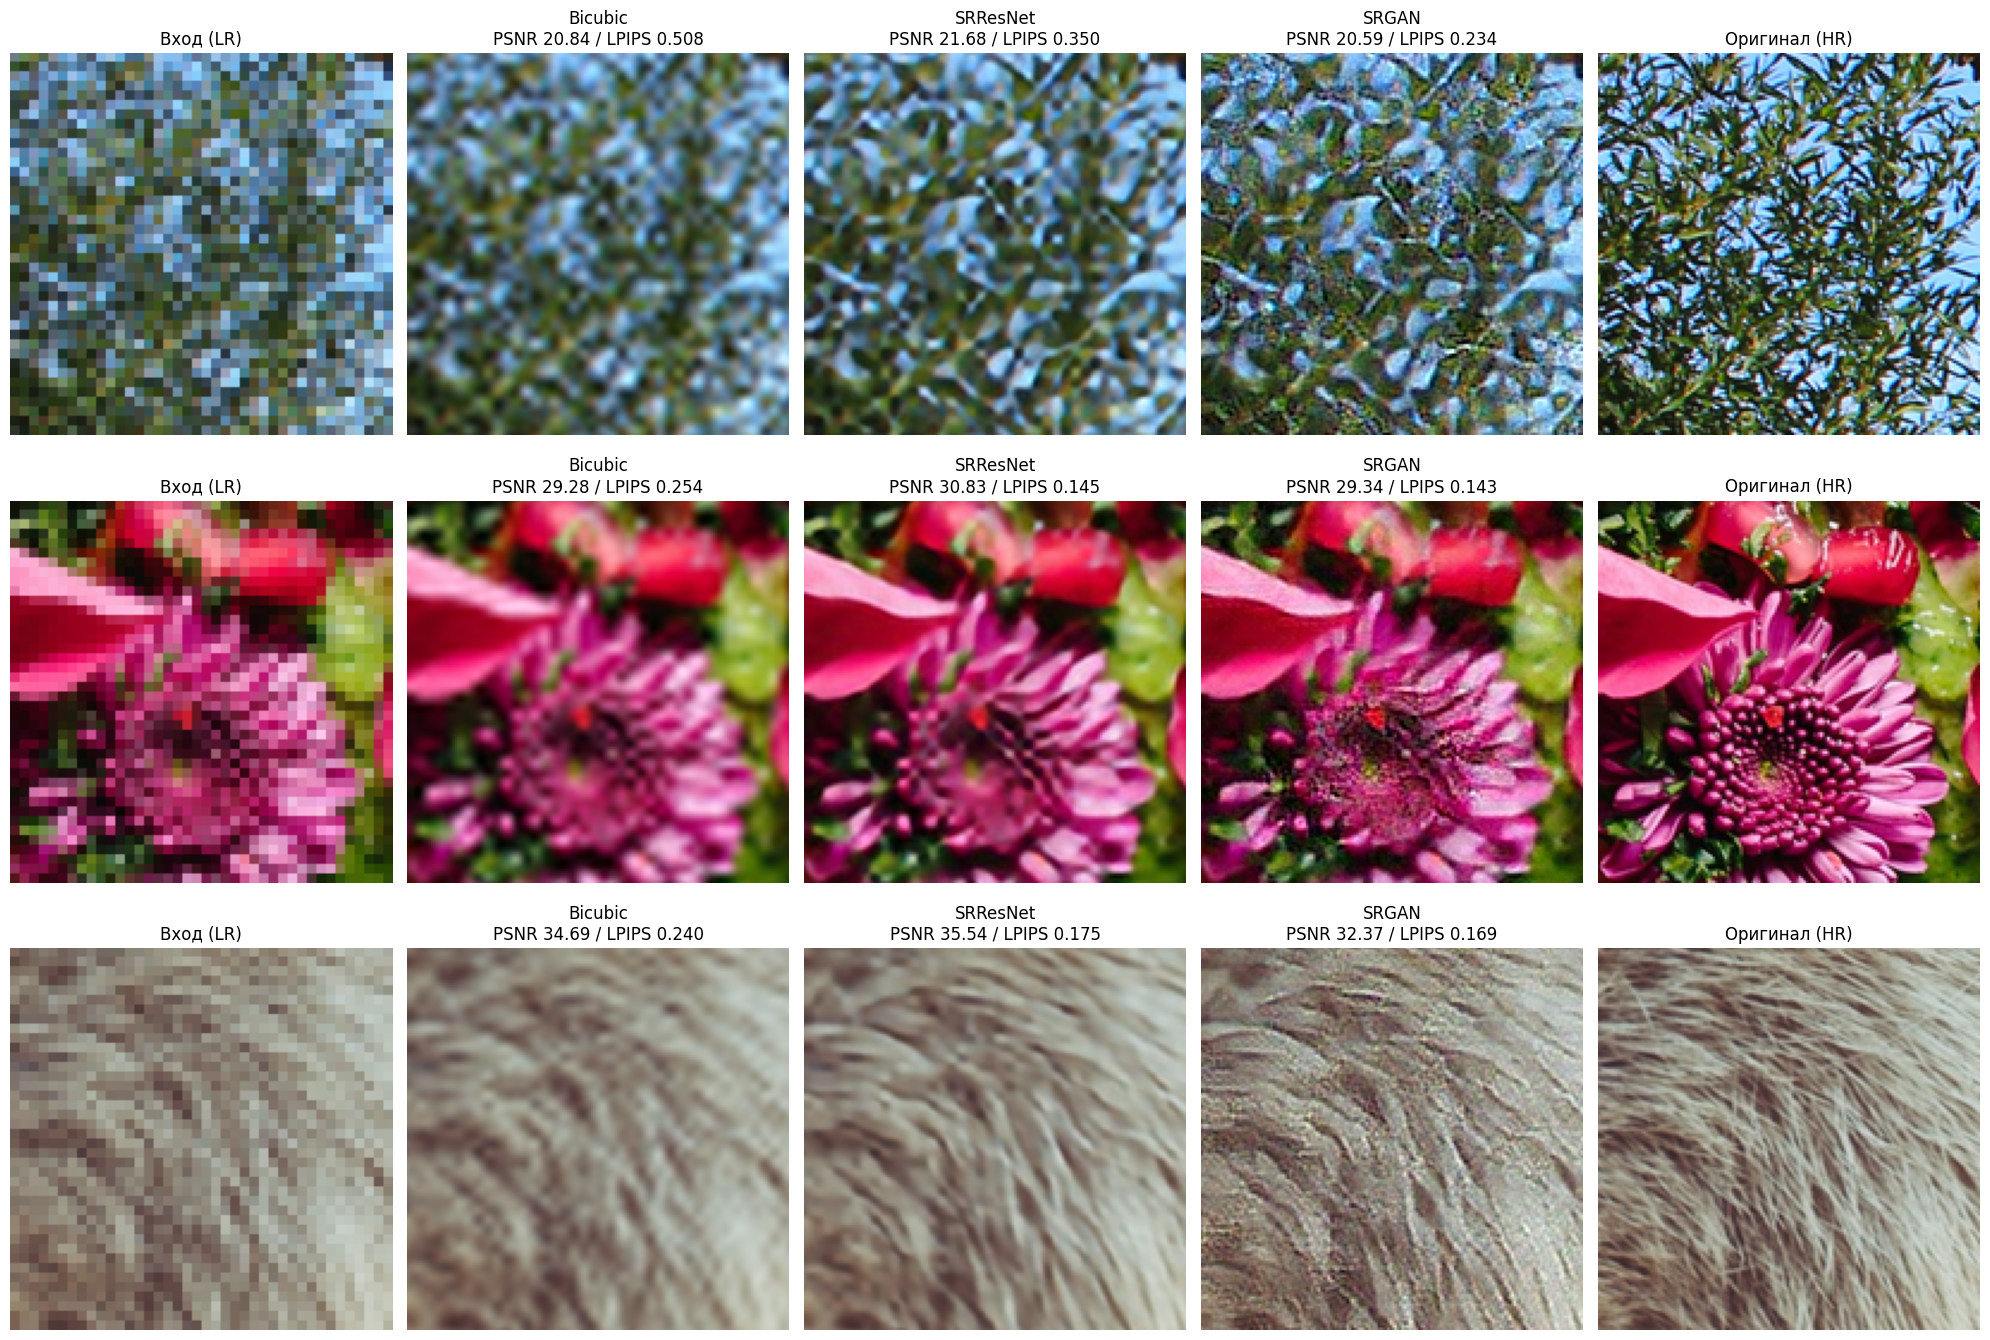

In [9]:
def detailed_crop(img, size):
    # Находит квадрат size×size с наибольшим количеством мелких деталей и возвращает координаты его левого верхнего угла
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    # Резкие перепады яркости: контуры, узоры, текстуры
    edges = np.abs(cv2.Laplacian(gray, cv2.CV_32F))
    # Среднее количество перепадов в квадрате вокруг каждой точки
    density = cv2.boxFilter(edges, -1, (size, size))
    h, w = gray.shape
    half = size // 2
    # Только центры, у которых квадрат целиком помещается в фото
    inner = density[half:h - half, half:w - half]
    y, x = np.unravel_index(np.argmax(inner), inner.shape)
    # Координаты кратны SCALE, чтобы фрагмент точно совпадал с фрагментом маленького фото
    return y - y % SCALE, x - x % SCALE


# Размер показываемого фрагмента в пикселях большого фото
CROP = 160
# Номера проверочных фото для показа
SHOW_IDS = [0, 33, 66]

fig, axes = plt.subplots(len(SHOW_IDS), 5, figsize=(20, 4.6 * len(SHOW_IDS)))
for row, idx in zip(axes, SHOW_IDS):
    lr_img, hr_img = valid_lr[idx], valid_hr[idx]
    y, x = detailed_crop(hr_img, CROP)

    # Фрагмент маленького фото увеличен повторением пикселей, чтобы было видно исходное качество
    lr_part = lr_img[y // SCALE:(y + CROP) // SCALE, x // SCALE:(x + CROP) // SCALE]
    parts = [("Вход (LR)", cv2.resize(lr_part, (CROP, CROP), interpolation=cv2.INTER_NEAREST))]

    # Метрики в подписи посчитаны по всему фото
    for name, upscale in methods.items():
        sr = upscale(lr_img)
        title = f"{name}\nPSNR {results[name]['PSNR'][idx]:.2f} / LPIPS {results[name]['LPIPS'][idx]:.3f}"
        parts.append((title, sr[y:y + CROP, x:x + CROP]))
    parts.append(("Оригинал (HR)", hr_img[y:y + CROP, x:x + CROP]))

    for ax, (title, img) in zip(row, parts):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Графики обучения

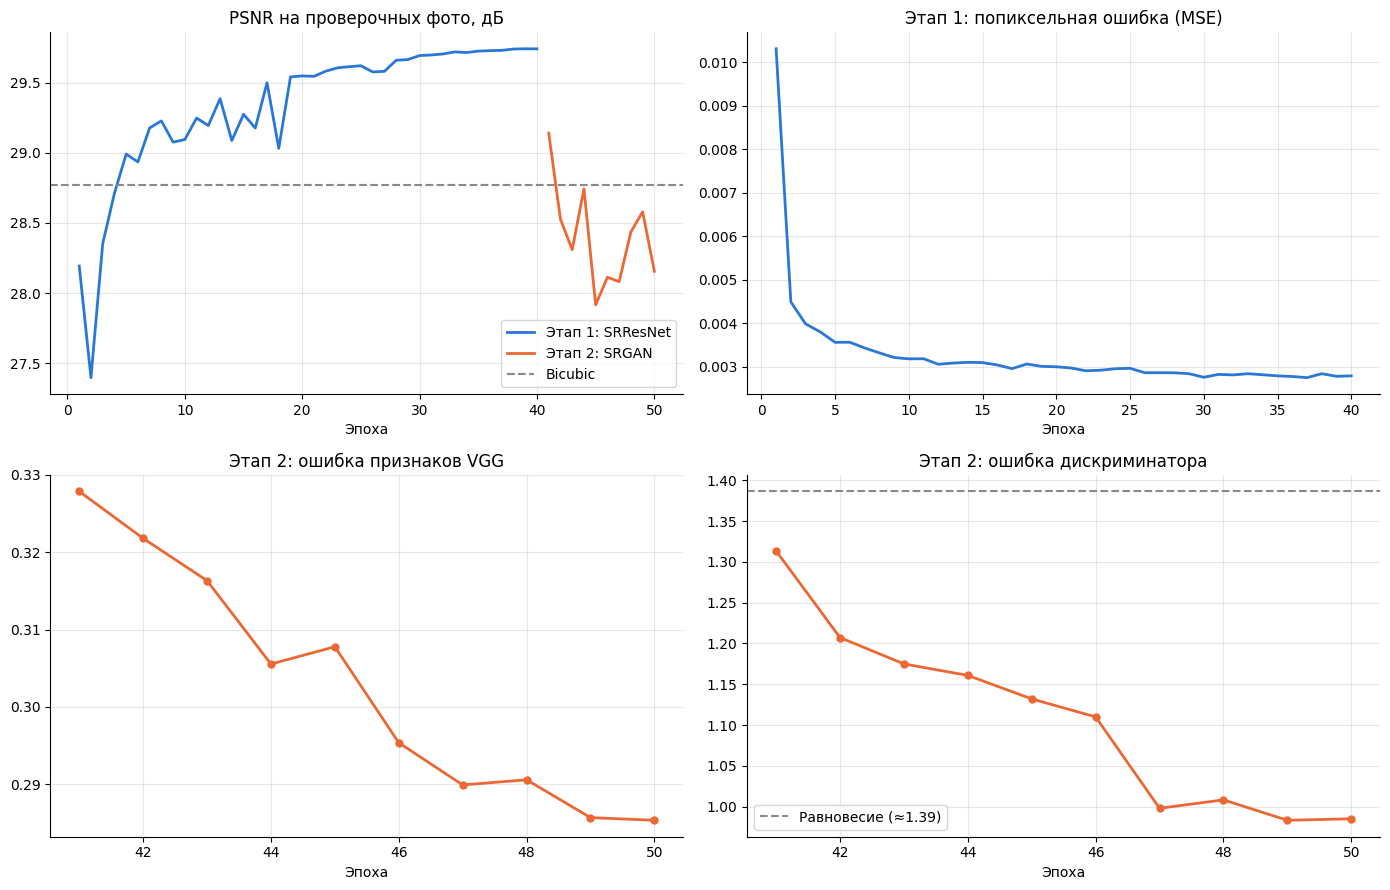

In [10]:
# Цвета линий: синий — первый этап, оранжевый — второй этап, серый — обычное увеличение
COLOR_PRE, COLOR_GAN, COLOR_BASE = "#2a78d6", "#eb6834", "#8a8984"

epochs_pre = np.arange(1, len(history_pre) + 1)
# Эпохи второго этапа продолжают нумерацию первого
epochs_gan = np.arange(1, len(history_gan) + 1) + len(history_pre)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# PSNR на быстрой проверке по ходу обоих этапов
ax = axes[0, 0]
ax.plot(epochs_pre, [h[1] for h in history_pre], color=COLOR_PRE, lw=2, label="Этап 1: SRResNet")
ax.plot(epochs_gan, [h[4] for h in history_gan], color=COLOR_GAN, lw=2, label="Этап 2: SRGAN")
ax.axhline(quick_psnr(bicubic_upscale), color=COLOR_BASE, lw=1.5, ls="--", label="Bicubic")
ax.set_title("PSNR на проверочных фото, дБ")
ax.set_xlabel("Эпоха")
ax.legend()

# Ошибка первого этапа
ax = axes[0, 1]
ax.plot(epochs_pre, [h[0] for h in history_pre], color=COLOR_PRE, lw=2)
ax.set_title("Этап 1: попиксельная ошибка (MSE)")
ax.set_xlabel("Эпоха")

# Ошибка сравнения признаков VGG на втором этапе
ax = axes[1, 0]
ax.plot(epochs_gan, [h[1] for h in history_gan], color=COLOR_GAN, lw=2, marker="o", ms=5)
ax.set_title("Этап 2: ошибка признаков VGG")
ax.set_xlabel("Эпоха")

# Ошибка дискриминатора на втором этапе; около 1.39 — дискриминатор не отличает настоящее от созданного
ax = axes[1, 1]
ax.plot(epochs_gan, [h[3] for h in history_gan], color=COLOR_GAN, lw=2, marker="o", ms=5)
ax.axhline(2 * np.log(2), color=COLOR_BASE, lw=1.5, ls="--", label="Равновесие (≈1.39)")
ax.set_title("Этап 2: ошибка дискриминатора")
ax.set_xlabel("Эпоха")
ax.legend()

# Светлая сетка
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 10. Демонстрация на своём фото

Фото для демонстрации — файл `image.png` рядом с ноутбуком. Если большая сторона фото больше 512 пикселей, оно считается оригиналом: уменьшается в 4 раза, восстанавливается и сравнивается с оригиналом. Фото меньшего размера сразу увеличивается в 4 раза.

Результат SRGAN сохраняется в папку `results`.

Оригинал 1024x572 уменьшен в 4 раза до 256x143 и восстановлен


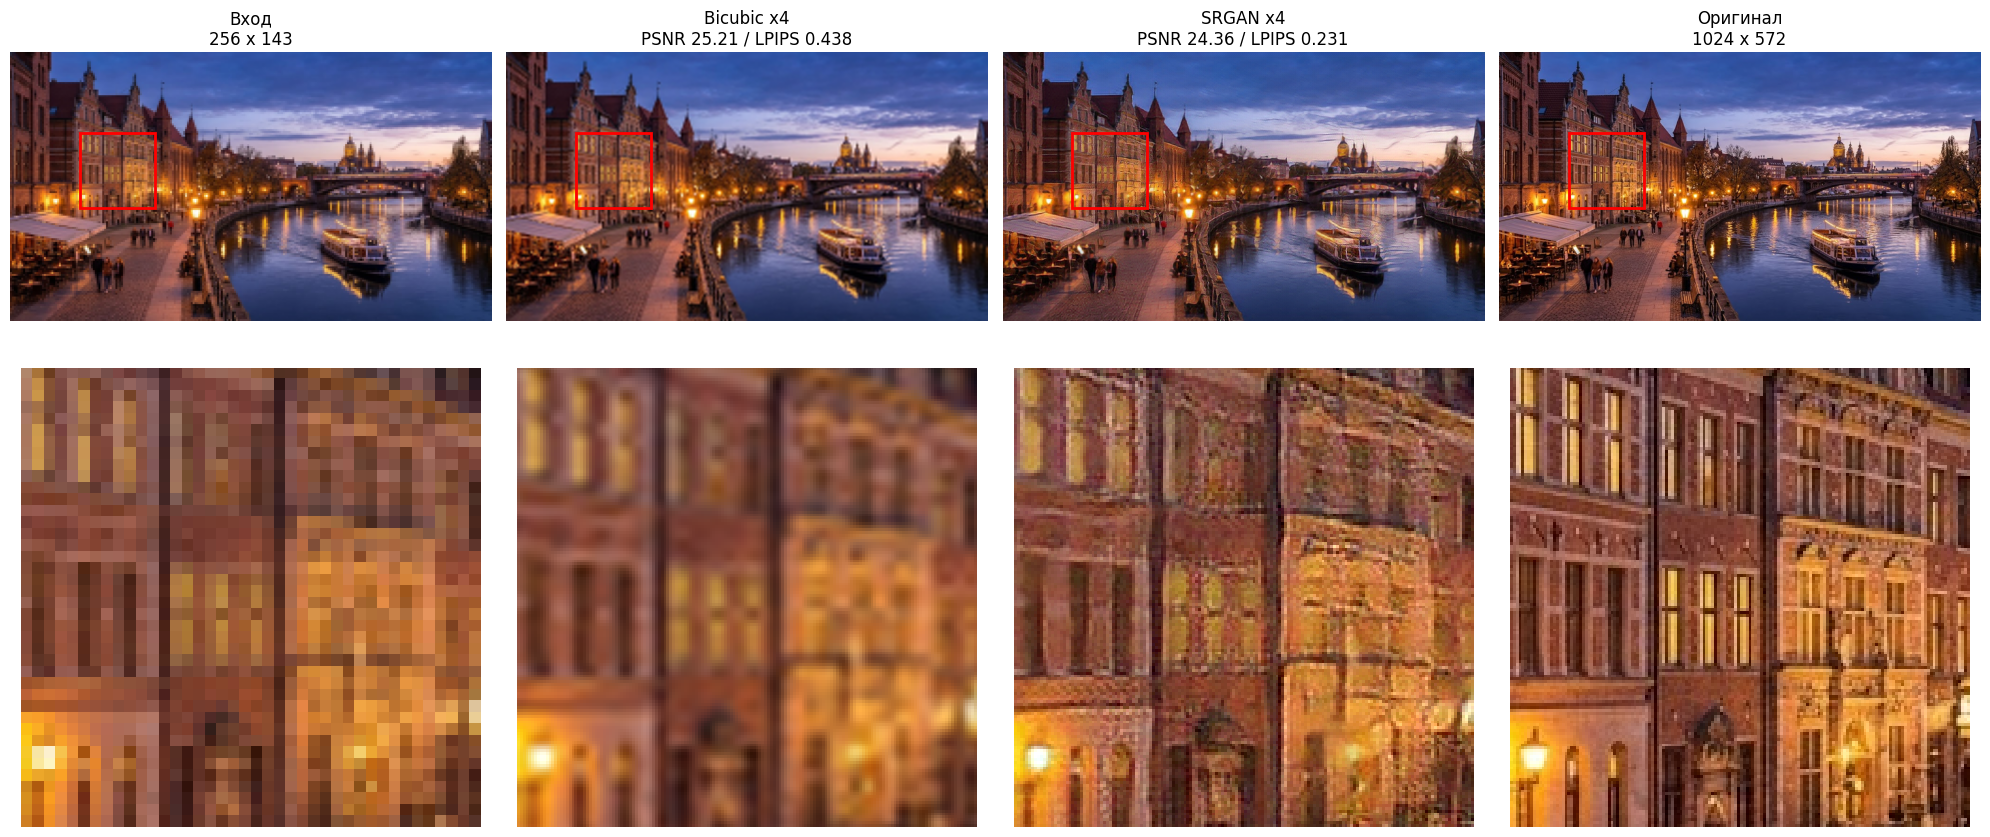

Результат сохранён


In [13]:
# Своё фото рядом с ноутбуком
DEMO_IMAGE = Path("image.png")
# Фото больше этого размера считается оригиналом: из него делается уменьшенная копия, которая затем восстанавливается
MAX_INPUT_SIDE = 512
# Наибольшая сторона оригинала
MAX_HR_SIDE = MAX_INPUT_SIDE * SCALE


def resize_to_max_side(img, max_side):
    # Уменьшает фото так, чтобы большая сторона была не больше max_side; фото меньшего размера не меняется
    h, w = img.shape[:2]
    if max(h, w) <= max_side:
        return img
    k = max_side / max(h, w)
    return cv2.resize(img, (round(w * k), round(h * k)), interpolation=cv2.INTER_AREA)


if not DEMO_IMAGE.exists():
    raise FileNotFoundError(f"Нет файла {DEMO_IMAGE}")
img = load_image(DEMO_IMAGE)

if max(img.shape[:2]) > MAX_INPUT_SIDE:
    # Большое фото: оригинал уменьшается в SCALE раз, чтобы потом сравнить с ним восстановленный результат
    hr_img = crop_to_scale(resize_to_max_side(img, MAX_HR_SIDE))
    lr_img = downscale(hr_img)
    print(f"Оригинал {hr_img.shape[1]}x{hr_img.shape[0]} уменьшен в {SCALE} раза до "
          f"{lr_img.shape[1]}x{lr_img.shape[0]} и восстановлен")
else:
    # Маленькое фото: сразу увеличивается, оригинала для сравнения нет
    hr_img = None
    lr_img = img

sr_img = super_resolve(generator, lr_img)
bic_img = bicubic_upscale(lr_img)
out_h, out_w = sr_img.shape[:2]

# Вход растянут повторением пикселей до размера результата, чтобы фрагменты совпадали по месту
lr_show = cv2.resize(lr_img, (out_w, out_h), interpolation=cv2.INTER_NEAREST)
parts = [(f"Вход\n{lr_img.shape[1]} x {lr_img.shape[0]}", lr_show)]
for title, result in [(f"Bicubic x{SCALE}", bic_img), (f"SRGAN x{SCALE}", sr_img)]:
    if hr_img is not None:
        title += f"\nPSNR {psnr(result, hr_img):.2f} / LPIPS {lpips_score(result, hr_img):.3f}"
    else:
        title += f"\n{out_w} x {out_h}"
    parts.append((title, result))
if hr_img is not None:
    parts.append((f"Оригинал\n{out_w} x {out_h}", hr_img))

# Фрагмент с наибольшим количеством деталей
y, x = detailed_crop(hr_img if hr_img is not None else sr_img, CROP)

# Верхний ряд: фото целиком с рамкой фрагмента; нижний ряд: сам фрагмент крупно
fig, axes = plt.subplots(2, len(parts), figsize=(5 * len(parts), 9))
for col, (title, picture) in enumerate(parts):
    axes[0, col].imshow(picture)
    axes[0, col].add_patch(plt.Rectangle((x, y), CROP, CROP, fill=False, edgecolor="red", linewidth=2))
    axes[0, col].set_title(title)
    axes[1, col].imshow(picture[y:y + CROP, x:x + CROP], interpolation="nearest")
    for ax in axes[:, col]:
        ax.axis("off")
plt.tight_layout()
plt.show()

# Сохранение результата SRGAN без потери качества
cv2.imwrite(str(RESULTS_DIR / f"{DEMO_IMAGE.stem}_srgan_x{SCALE}.png"), cv2.cvtColor(sr_img, cv2.COLOR_RGB2BGR))
print("Результат сохранён")

## Выводы

1. **Реализована и обучена SRGAN для увеличения изображений в 4 раза** (PyTorch). Генератор — SRResNet из 16 остаточных блоков (1.55 млн параметров), дискриминатор — 8 свёрточных блоков (23.6 млн параметров), перцептивная ошибка считается по признакам VGG19.

2. **Набор данных создан из открытого датасета DIV2K**: 700 фото для обучения, 100 для проверки. Пары «маленькое → большое» получаются уменьшением случайных кусков 96×96 до 24×24 через `cv2.resize`.

3. **Обучение в два этапа:** 40 эпох SRResNet с попиксельной ошибкой, затем 10 эпох SRGAN с дискриминатором.

4. **Результаты на 100 проверочных фото:**

| Метод | PSNR, дБ ↑ | SSIM ↑ | LPIPS ↓ |
|---|---|---|---|
| Bicubic | 28.78 | 0.8019 | 0.3881 |
| SRResNet | **29.82** | **0.8326** | 0.2897 |
| SRGAN | 28.09 | 0.7697 | **0.2068** |

5. **SRResNet точнее всех по пикселям** (+1.04 дБ к bicubic), но мелкие детали превращаются в гладкие пятна: при неуверенности сеть выдаёт усреднённый вариант. **SRGAN уступает по PSNR и SSIM, но лучше всех по LPIPS** (на 29% лучше SRResNet и на 47% лучше bicubic): она восстанавливает текстуры (листва, лепестки, шерсть). Это подтверждает вывод статьи: PSNR плохо отражает качество картинки так, как его видит человек.

6. **По графикам обучения:** PSNR SRResNet растёт и к 30-й эпохе выходит на ≈29.7 дБ. На втором этапе PSNR падает ниже уровня bicubic и колеблется от 27.9 до 29.1 дБ: генератор жертвует точностью пикселей ради правдоподобных деталей. Ошибка признаков VGG снижается с 0.328 до 0.285. Ошибка дискриминатора падает с 1.31 до ≈0.99, ниже уровня равновесия 1.39: дискриминатор постепенно сильнее генератора, но обучение не разрушилось.

7. **На своём фото** (вечерняя набережная, оригинал 1024×572 уменьшен до 256×143) картина та же: SRGAN уступает bicubic по PSNR (24.36 против 25.21 дБ), но заметно лучше по LPIPS (0.231 против 0.438). На увеличенном фрагменте SRGAN восстанавливает сетку окон и фактуру кирпича, которые bicubic размывает, но мелкий декор фасада и оконные рамы дорисованы неточно и покрыты шумом.

8. **Ограничения.** Второй этап короткий (7 000 шагов против 200 000 в статье), поэтому на сложных текстурах заметны шум и сетчатые узоры. SRGAN **дорисовывает правдоподобные, но не настоящие детали**, поэтому для задач, где важна точность (распознавание номеров, лиц), её результат нельзя считать достоверным: там надёжнее SRResNet.

9. **Возможные улучшения:** более долгое обучение; архитектура ESRGAN (блоки RRDB без BatchNorm, относительный дискриминатор); обучение на фото с размытием, шумом и сжатием JPEG для работы с реальными снимками плохого качества.